# 🏢MNC Growth📈and Workforce Analytics🔎Using Python💻

*  **Dataset Name**:Inc 5000 Companies dataset
*  **Original Source**:https://mavenanalytics.io/data-playground
*  **Domain**: Finance
*  **Expected size**:14 fields,502 Rows
*  Dataset Containing information about each     company on the 2019 Inc 5000 list
*  **Time line** : 1909 - 2015
* **Location** :The dataset contains companies across 43 states, 293 cities and 54 distinct metropolitan-area labels

In [ ]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project Objectives:

1. Analyze Company Growth

     Identify companies with the highest revenue growth percentage.

2. Compare Industry Performance

     Determine which industries generate the highest total revenue and have the largest workforce.

3. Evaluate Workforce Growth

     Identify companies with the highest employee growth compared to their previous workforce.

4. Analyze Geographical Distribution

     Identify the states and cities with the highest number of companies and compare business performance by location.

5. Study Revenue and Growth Trends

     Analyze the relationship between company revenue and revenue growth percentage.

6. Analyze Revenue per Employee

     Identify companies with the highest revenue per employee to evaluate workforce productivity.

7. Study Company Age and Business Trends

     Analyze the distribution of companies across founding years, compare the growth of newer and older companies, and identify industries with the highest and lowest representation.

Step 1: Check and load the Dataset

In [ ]:
# Load the dataset

url = "https://raw.githubusercontent.com/itsmeangell30-cpu/Company-Growth-and-Workforce-Analytics-Using-Python/refs/heads/main/Original%20dataset.csv"

df = pd.read_csv(url)

In [ ]:
# Display the first 5 rows
print(df.head())

   Rank                                   Profile               Name  \
0     1      https://www.inc.com/profile/freestar           Freestar   
1     2   https://www.inc.com/profile/freightwise        FreightWise   
2     3  https://www.inc.com/profile/ceces-veggie  Cece's Veggie Co.   
3     4      https://www.inc.com/profile/ladyboss           LadyBoss   
4     5        https://www.inc.com/profile/perpay             Perpay   

                         url state       Revenue    Growth_%  \
0        http://freestar.com    AZ  36.9 Million  36680.3882   
1  http://freightwisellc.com    TN  33.6 Million  30547.9317   
2   http://cecesveggieco.com    TX  24.9 Million  23880.4852   
3        http://ladyboss.com    NM  32.4 Million  21849.8925   
4          http://perpay.com    PA  22.5 Million  18166.4070   

                       Industry  workers  previous_workers  Founded  \
0       Advertising & Marketing       40                 5     2015   
1    Logistics & Transportation       39

# Initial EDA (Exploratory Data Analysis

In [ ]:
# Display the number of rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
display(df.head(10))

Number of rows: 502
Number of columns: 14


,Rank,Profile,Name,url,state,Revenue,Growth_%,Industry,workers,previous_workers,Founded,yrs_on_list,Metro,city
0,1,https://www.inc.com/profile/freestar,Freestar,http://freestar.com,AZ,36.9 Million,36680.3882,Advertising & Marketing,40,5,2015,1,Phoenix,Phoenix
1,2,https://www.inc.com/profile/freightwise,FreightWise,http://freightwisellc.com,TN,33.6 Million,30547.9317,Logistics & Transportation,39,8,2015,1,Nashville,Brentwood
2,3,https://www.inc.com/profile/ceces-veggie,Cece's Veggie Co.,http://cecesveggieco.com,TX,24.9 Million,23880.4852,Food & Beverage,190,10,2015,1,Austin,Austin
3,4,https://www.inc.com/profile/ladyboss,LadyBoss,http://ladyboss.com,NM,32.4 Million,21849.8925,Consumer Products & Services,57,2,2014,1,NaN,Albuquerque
4,5,https://www.inc.com/profile/perpay,Perpay,http://perpay.com,PA,22.5 Million,18166.4070,Retail,25,6,2014,1,Philadelphia,Philadelphia
5,6,https://www.inc.com/profile/cano-health,Cano Health,http://canohealth.com,FL,271.8 Million,14183.4118,Health,742,18,2009,1,Miami,Miami
6,7,https://www.inc.com/profile/bear-mattress,Bear Mattress,http://bearmattress.com,NJ,20.5 Million,13480.7310,Consumer Products & Services,12,1,2014,1,New York City,Hoboken
7,8,https://www.inc.com/profile/connected-solution...,Connected Solutions Group,http://csgstore.net,VA,23.3 Million,12700.6588,Telecommunications,72,1,2015,1,"Richmond, VA",Mechanicsville
8,9,https://www.inc.com/profile/providence-healthc...,Providence Healthcare Management,http://providencehcm.com,OH,225.9 Million,12564.5364,Health,60,10,2008,1,Cleveland,Cleveland
9,10,https://www.inc.com/profile/nom,NOM,http://thisisnom.co,CA,21.4 Million,11996.2964,Advertising & Marketing,37,5,2014,1,Los Angeles,Los Angeles


In [ ]:
# Column names
print("Column names:")
print(df.columns.tolist())

Column names:
['Rank', 'Profile', 'Name', 'url', 'state', 'Revenue', 'Growth_%', 'Industry', 'workers', 'previous_workers', 'Founded', 'yrs_on_list', 'Metro', 'city']


In [ ]:
# Data types and non-null counts
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 502 entries, 0 to 501
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Rank              502 non-null    int64  
 1   Profile           502 non-null    object 
 2   Name              502 non-null    object 
 3   url               502 non-null    object 
 4   state             502 non-null    object 
 5   Revenue           502 non-null    object 
 6   Growth_%          502 non-null    float64
 7   Industry          502 non-null    object 
 8   workers           502 non-null    int64  
 9   previous_workers  502 non-null    int64  
 10  Founded           502 non-null    int64  
 11  yrs_on_list       502 non-null    int64  
 12  Metro             432 non-null    object 
 13  city              502 non-null    object 
dtypes: float64(1), int64(5), object(8)
memory usage: 55.0+ KB


In [ ]:
# Display statistical summary
print("Numerical summary:")
print(df.describe())

Numerical summary:
             Rank      Growth_%      workers  previous_workers      Founded  \
count  502.000000    502.000000   502.000000        502.000000   502.000000   
mean   250.665339   2717.964251   103.561753         15.709163  2012.025896   
std    144.820198   3245.585941   288.018198         40.545717     5.980451   
min      1.000000    868.610000     0.000000          1.000000  1909.000000   
25%    125.250000   1225.722200    18.000000          2.000000  2012.000000   
50%    250.500000   1701.402900    38.000000          5.000000  2013.000000   
75%    375.750000   2779.573250    80.750000         13.000000  2014.000000   
max    501.000000  36680.388200  4572.000000        500.000000  2015.000000   

       yrs_on_list  
count   502.000000  
mean      1.382470  
std       0.732161  
min       1.000000  
25%       1.000000  
50%       1.000000  
75%       2.000000  
max       8.000000  


# Data Cleaning,Data Transformation  and Feature Engineering

Step 2 : Check and remove Duplicate rows

In [ ]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


Step 3: Find and handle missing values

In [ ]:
# Check missing values in each column
print(df.isnull().sum())

Rank                 0
Profile              0
Name                 0
url                  0
state                0
Revenue              0
Growth_%             0
Industry             0
workers              0
previous_workers     0
Founded              0
yrs_on_list          0
Metro               70
city                 0
dtype: int64


In [ ]:
# Step 1: Replace "Unknown" with missing values in Metro
df["Metro"] = df["Metro"].replace("Unknown", pd.NA)

In [ ]:
# Fill missing Metro values using the city column
df["Metro"] = df["Metro"].fillna(df["city"])

In [ ]:
# Check missing values after filling
print("Missing values in Metro:", df["Metro"].isnull().sum())

Missing values in Metro: 0


In [ ]:
# Display city and Metro columns
print(df[["city", "Metro"]].head(10))

             city          Metro
0         Phoenix        Phoenix
1       Brentwood      Nashville
2          Austin         Austin
3     Albuquerque    Albuquerque
4    Philadelphia   Philadelphia
5           Miami          Miami
6         Hoboken  New York City
7  Mechanicsville   Richmond, VA
8       Cleveland      Cleveland
9     Los Angeles    Los Angeles


If we have missing values and (ie) Empty cells and also Unknown values ..in that case first we need to replace Unknown with NA.Then we need to use "fillna" to replace all missing values .so that we dont get error.

Step 4: Rename columns

In [ ]:
# Rename columns
df = df.rename(columns={
    "Name": "Company_name",
    "Revenue": "Revenue_in_millions",
    "Growth_%": "Revenue_Growth_Percentage",
    "yrs_on_list": "Years_On_List",
    "previous_workers": "Previous_Workers",
    "workers": "Current_Workers"
})

In [ ]:
# Display the new column names
print(df.columns.tolist())

['Rank', 'Profile', 'Company_name', 'url', 'state', 'Revenue_in_millions', 'Revenue_Growth_Percentage', 'Industry', 'Current_Workers', 'Previous_Workers', 'Founded', 'Years_On_List', 'Metro', 'city']


Step 5: Data transformation

Data transformation means changing data into a more useful format for analysis.

Here, we will create employee growth information using current and previous worker counts.

A. Convert data types
     
     Revenue column contains text values such as "36.9 Million". To perform mathematical calculations, convert it into a numeric column.

In [ ]:
# Remove the word Million and convert Revenue to float
df["Revenue_in_millions"] = df["Revenue_in_millions"].str.replace(" Million", "", regex=False).astype(float)

In [ ]:
# Check the data type
print(df["Revenue_in_millions"].dtype)

float64


In [ ]:
# Display the first 5 rows
print(df[["Revenue_in_millions"]].head())

   Revenue_in_millions
0                 36.9
1                 33.6
2                 24.9
3                 32.4
4                 22.5


Now datatype is changed from 'Object' to 'float'

A. Round revenue growth percentage

In [ ]:
df["Revenue_Growth_Percentage"] = (
    df["Revenue_Growth_Percentage"].round(2)
)

In [ ]:
# Display the first 5 rows
print(df[["Revenue_Growth_Percentage"]].head())

   Revenue_Growth_Percentage
0                   36680.39
1                   30547.93
2                   23880.49
3                   21849.89
4                   18166.41


B. Standardize text columns

In [ ]:
# Remove extra spaces from all text columns
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].str.strip()

In [ ]:
# Display the first 5 rows
print(df.head())

   Rank                                   Profile       Company_name  \
0     1      https://www.inc.com/profile/freestar           Freestar   
1     2   https://www.inc.com/profile/freightwise        FreightWise   
2     3  https://www.inc.com/profile/ceces-veggie  Cece's Veggie Co.   
3     4      https://www.inc.com/profile/ladyboss           LadyBoss   
4     5        https://www.inc.com/profile/perpay             Perpay   

                         url state  Revenue_in_millions  \
0        http://freestar.com    AZ                 36.9   
1  http://freightwisellc.com    TN                 33.6   
2   http://cecesveggieco.com    TX                 24.9   
3        http://ladyboss.com    NM                 32.4   
4          http://perpay.com    PA                 22.5   

   Revenue_Growth_Percentage                      Industry  Current_Workers  \
0                   36680.39       Advertising & Marketing               40   
1                   30547.93    Logistics & Transporta

Step 6: Feature engineering

Feature engineering means creating new columns from existing data to gain additional insights.

We will create two useful features: company age at a specified reference year and a company size category.

In [ ]:
# Calculate employee change
df["Employee_Change"] = df["Current_Workers"] - df["Previous_Workers"]

# Calculate employee growth percentage and round to 2 decimals
df["Employee_Growth_Percentage"] = ((df["Employee_Change"] / df["Previous_Workers"]) * 100).round(2)

print(df["Employee_Growth_Percentage"].head())

0     700.00
1     387.50
2    1800.00
3    2750.00
4     316.67
Name: Employee_Growth_Percentage, dtype: float64


Purpose: This helps you understand how the number of employees has changed between the two reported periods.

In [ ]:
# Categorize companies based on current workers
def company_size(workers):
    if workers < 50:
        return "Small"
    elif workers < 250:
        return "Medium"
    else:
        return "Large"

df["Company_Size"] = df["Current_Workers"].apply(company_size)

print(df["Company_Size"])

0       Small
1       Small
2      Medium
3      Medium
4       Small
        ...  
497    Medium
498     Small
499     Small
500    Medium
501     Small
Name: Company_Size, Length: 502, dtype: object


In [ ]:
# Calculate company age as of 2015
df["Company_Age"] = 2015 - df["Founded"]

# Display the result
print(df[["Company_name", "Founded", "Company_Age"]].head())

        Company_name  Founded  Company_Age
0           Freestar     2015            0
1        FreightWise     2015            0
2  Cece's Veggie Co.     2015            0
3           LadyBoss     2014            1
4             Perpay     2014            1


In [ ]:
# Check zero values in worker columns
print("Zero values in Previous_Workers:",
      (df["Previous_Workers"] == 0).sum())

print("Zero values in Current_Workers:",
      (df["Current_Workers"] == 0).sum())

Zero values in Previous_Workers: 0
Zero values in Current_Workers: 1


In [ ]:
# Chcking which row has Zero value.
print(df[df["Current_Workers"] == 0])

     Rank                                  Profile Company_name  \
245   245  https://www.inc.com/profile/tier4-group  Tier4 Group   

                       url state  Revenue_in_millions  \
245  http://tier4group.com    GA                  4.6   

     Revenue_Growth_Percentage                      Industry  Current_Workers  \
245                     1729.4  Business Products & Services                0   

     Previous_Workers  Founded  Years_On_List    Metro     city  \
245                 3     2010              1  Atlanta  Atlanta   

     Employee_Change  Employee_Growth_Percentage Company_Size  Company_Age  
245               -3                      -100.0        Small            5  


In [ ]:
df["Revenue_Per_Employee"] = (
    (df["Revenue_in_millions"] * 1000000) / df["Current_Workers"].replace(0, float("nan"))
).round(2)

Since Revenue_in_million column contains revenue in millions, you need to multiply it by 1,000,000 to convert it into the actual amount before calculating revenue per employee.

In [ ]:
# Display calculated columns
print(df[[
    "Company_name",
    "Employee_Change",
    "Employee_Growth_Percentage",
    "Revenue_Per_Employee"
]].head(10))

                       Company_name  Employee_Change  \
0                          Freestar               35   
1                       FreightWise               31   
2                 Cece's Veggie Co.              180   
3                          LadyBoss               55   
4                            Perpay               19   
5                       Cano Health              724   
6                     Bear Mattress               11   
7         Connected Solutions Group               71   
8  Providence Healthcare Management               50   
9                               NOM               32   

   Employee_Growth_Percentage  Revenue_Per_Employee  
0                      700.00             922500.00  
1                      387.50             861538.46  
2                     1800.00             131052.63  
3                     2750.00             568421.05  
4                      316.67             900000.00  
5                     4022.22             366307.28  
6    

In [ ]:
# Check missing values in calculation columns
columns = [
    "Revenue_in_millions",
    "Previous_Workers",
    "Current_Workers",
    "Employee_Change",
    "Employee_Growth_Percentage",
    "Company_Age"
]

print(df[columns].isnull().sum())

Revenue_in_millions           0
Previous_Workers              0
Current_Workers               0
Employee_Change               0
Employee_Growth_Percentage    0
Company_Age                   0
dtype: int64


Step 9: Final EDA (Exploratory Data Analysis)

After cleaning and transforming the dataset, check the final results.

In [ ]:
# Display first 5 rows
print(df.head())

   Rank                                   Profile       Company_name  \
0     1      https://www.inc.com/profile/freestar           Freestar   
1     2   https://www.inc.com/profile/freightwise        FreightWise   
2     3  https://www.inc.com/profile/ceces-veggie  Cece's Veggie Co.   
3     4      https://www.inc.com/profile/ladyboss           LadyBoss   
4     5        https://www.inc.com/profile/perpay             Perpay   

                         url state  Revenue_in_millions  \
0        http://freestar.com    AZ                 36.9   
1  http://freightwisellc.com    TN                 33.6   
2   http://cecesveggieco.com    TX                 24.9   
3        http://ladyboss.com    NM                 32.4   
4          http://perpay.com    PA                 22.5   

   Revenue_Growth_Percentage                      Industry  Current_Workers  \
0                   36680.39       Advertising & Marketing               40   
1                   30547.93    Logistics & Transporta

In [ ]:
# To display the entire dataset in a table in Google Colab
display(df)

,Rank,Profile,Company_name,url,state,Revenue_in_millions,Revenue_Growth_Percentage,Industry,Current_Workers,Previous_Workers,Founded,Years_On_List,Metro,city,Employee_Change,Employee_Growth_Percentage,Company_Size,Company_Age,Revenue_Per_Employee
0,1,https://www.inc.com/profile/freestar,Freestar,http://freestar.com,AZ,36.9,36680.39,Advertising & Marketing,40,5,2015,1,Phoenix,Phoenix,35,700.00,Small,0,922500.00
1,2,https://www.inc.com/profile/freightwise,FreightWise,http://freightwisellc.com,TN,33.6,30547.93,Logistics & Transportation,39,8,2015,1,Nashville,Brentwood,31,387.50,Small,0,861538.46
2,3,https://www.inc.com/profile/ceces-veggie,Cece's Veggie Co.,http://cecesveggieco.com,TX,24.9,23880.49,Food & Beverage,190,10,2015,1,Austin,Austin,180,1800.00,Medium,0,131052.63
3,4,https://www.inc.com/profile/ladyboss,LadyBoss,http://ladyboss.com,NM,32.4,21849.89,Consumer Products & Services,57,2,2014,1,Albuquerque,Albuquerque,55,2750.00,Medium,1,568421.05
4,5,https://www.inc.com/profile/perpay,Perpay,http://perpay.com,PA,22.5,18166.41,Retail,25,6,2014,1,Philadelphia,Philadelphia,19,316.67,Small,1,900000.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
497,497,https://www.inc.com/profile/thought-logic-cons...,Thought Logic Consulting,thought-logic.com,GA,21.3,871.40,Business Products & Services,97,10,2013,3,Atlanta,Atlanta,87,870.00,Medium,2,219587.63
498,498,https://www.inc.com/profile/pbg-consulting,PBG Consulting,pbgconsult.com,VA,5.1,870.55,IT Management,28,2,2010,1,"Washington, DC",Mclean,26,1300.00,Small,5,182142.86
499,499,https://www.inc.com/profile/sarvicus,Sarvicus,sarvicus.com,TX,4.9,870.48,Telecommunications,15,2,2010,1,Houston,Houston,13,650.00,Small,5,326666.67
500,500,https://www.inc.com/profile/universal-processing,Universal Processing,uprocessing.com,NY,8.0,869.75,Financial Services,70,45,2003,1,New York City,New York,25,55.56,Medium,12,114285.71


In [ ]:
# Check rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (502, 19)


In [ ]:
# Check missing values
print(df.isnull().sum())

Rank                          0
Profile                       0
Company_name                  0
url                           0
state                         0
Revenue_in_millions           0
Revenue_Growth_Percentage     0
Industry                      0
Current_Workers               0
Previous_Workers              0
Founded                       0
Years_On_List                 0
Metro                         0
city                          0
Employee_Change               0
Employee_Growth_Percentage    0
Company_Size                  0
Company_Age                   0
Revenue_Per_Employee          1
dtype: int64


We are getting one NaN (missing value) in Revenue_Per_Employee because one company has 0 in its Current_Workers column.

Earlier, we replaced zero with NaN to prevent division by zero. Therefore, this result is expected.

Not replaced NaN with zero, because that would incorrectly suggest the company generates zero revenue per employee.

Your dataset can still be used for final EDA. Calculations such as average revenue per employee will automatically skip NaN values when using Pandas' .mean() method.

In [ ]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
# Statistical summary
print(df.describe())

             Rank  Revenue_in_millions  Revenue_Growth_Percentage  \
count  502.000000           502.000000                 502.000000   
mean   250.665339            24.373506                2717.964064   
std    144.820198            55.780469                3245.586127   
min      1.000000             2.000000                 868.610000   
25%    125.250000             4.300000                1225.722500   
50%    250.500000             8.050000                1701.405000   
75%    375.750000            20.800000                2779.575000   
max    501.000000           726.100000               36680.390000   

       Current_Workers  Previous_Workers      Founded  Years_On_List  \
count       502.000000        502.000000   502.000000     502.000000   
mean        103.561753         15.709163  2012.025896       1.382470   
std         288.018198         40.545717     5.980451       0.732161   
min           0.000000          1.000000  1909.000000       1.000000   
25%          18.00

In [ ]:
# Count companies in each industry
print(df["Industry"].value_counts())

Industry
Software                        65
Advertising & Marketing         51
Health                          42
Consumer Products & Services    39
Business Products & Services    34
Logistics & Transportation      30
Government Services             27
Retail                          26
Construction                    24
Financial Services              20
IT Management                   19
Real Estate                     17
Manufacturing                   15
Food & Beverage                 14
Energy                          13
Security                        11
IT System Development            9
Telecommunications               9
Human Resources                  9
Education                        7
Computer Hardware                5
Environmental Services           5
Travel & Hospitality             4
Media                            3
Insurance                        3
Engineering                      1
Name: count, dtype: int64


In [ ]:
# Count companies in each size category
print(df["Company_Size"].value_counts())

Company_Size
Small     298
Medium    163
Large      41
Name: count, dtype: int64


In [ ]:
# Top 10 companies by revenue growth
print(
    df.nlargest(10, "Revenue_Growth_Percentage")[
        ["Company_name", "Revenue_Growth_Percentage", "Revenue_in_millions"]
    ]
)

                       Company_name  Revenue_Growth_Percentage  \
0                          Freestar                   36680.39   
1                       FreightWise                   30547.93   
2                 Cece's Veggie Co.                   23880.49   
3                          LadyBoss                   21849.89   
4                            Perpay                   18166.41   
5                       Cano Health                   14183.41   
6                     Bear Mattress                   13480.73   
7         Connected Solutions Group                   12700.66   
8  Providence Healthcare Management                   12564.54   
9                               NOM                   11996.30   

   Revenue_in_millions  
0                 36.9  
1                 33.6  
2                 24.9  
3                 32.4  
4                 22.5  
5                271.8  
6                 20.5  
7                 23.3  
8                225.9  
9                 21.4 

In [ ]:
# Top 10 companies by employee growth
print(
    df.nlargest(10, "Employee_Growth_Percentage")[
        ["Company_name", "Employee_Growth_Percentage"]
    ]
)

                    Company_name  Employee_Growth_Percentage
119               SkillSet Group                     14700.0
143      Alpha Omega Integration                     14400.0
50   Nationwide Mortgage Bankers                      9900.0
168                       Ad Hoc                      9850.0
95                   Feedonomics                      8400.0
7      Connected Solutions Group                      7100.0
39                        Allata                      7000.0
66           Associated Veterans                      6300.0
146                   FedWriters                      5600.0
150                  Haga Kommer                      5400.0


In [ ]:
# Average revenue by industry/domain
print(df.groupby("Industry")["Revenue_in_millions"].mean().sort_values(ascending=False))

Industry
Health                          68.940476
Energy                          51.392308
Real Estate                     48.382353
Logistics & Transportation      39.460000
Financial Services              26.585000
Consumer Products & Services    25.741026
Insurance                       23.666667
Government Services             23.437037
Environmental Services          20.420000
Computer Hardware               19.140000
Advertising & Marketing         18.266667
Retail                          18.003846
Construction                    17.437500
Security                        17.263636
Human Resources                 14.922222
Education                       13.885714
Food & Beverage                 13.778571
Telecommunications              13.577778
Software                        13.196923
Business Products & Services    11.308824
Media                           10.566667
Manufacturing                    9.600000
IT Management                    8.663158
IT System Development    

In [ ]:
# Save the modified dataset
df.to_csv("Modified_Company_Growth_Dataset.csv", index=False)

print("Modified dataset saved successfully!")

Modified dataset saved successfully!


df.to_csv() saves your DataFrame as a CSV file.

index=False prevents Pandas from saving an extra index column.

**Statistical Analysis & Visualizations**

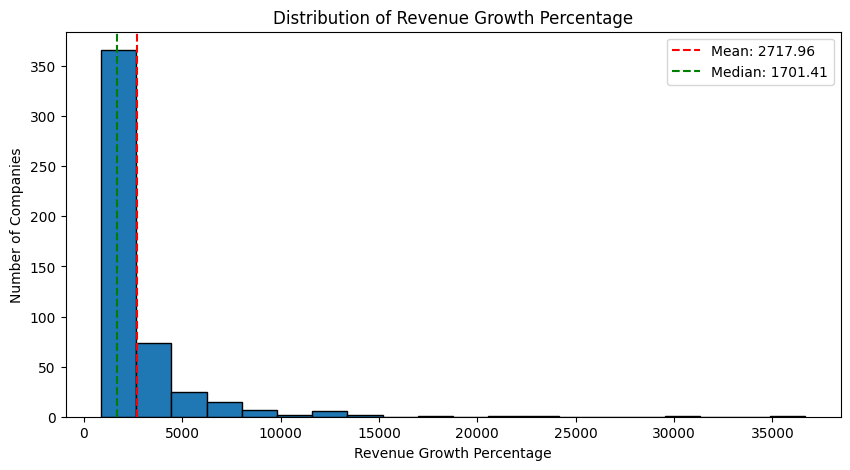

In [ ]:
# Calculate Mean and Median
mean_value = df["Revenue_Growth_Percentage"].mean()
median_value = df["Revenue_Growth_Percentage"].median()

# Create Histogram
plt.figure(figsize=(10, 5))

plt.hist(df["Revenue_Growth_Percentage"].dropna(),
         bins=20, edgecolor="black")

# Add Mean and Median lines
plt.axvline(mean_value, color="red", linestyle="--",
            label=f"Mean: {mean_value:.2f}")

plt.axvline(median_value, color="green", linestyle="--",
            label=f"Median: {median_value:.2f}")

# Add titles and labels
plt.title("Distribution of Revenue Growth Percentage")
plt.xlabel("Revenue Growth Percentage")
plt.ylabel("Number of Companies")

plt.legend()
plt.show()

1. Central Tendency-Interpretation

*   The Mean Revenue Growth Percentage is 2,717.96%, indicating the average    revenue growth among the companies.
*   The Median is 1,701.41%, showing that half of the companies have revenue growth below this value and half above it.
*   The mean is higher than the median, indicating a right-skewed distribution.
*   This suggests that a few companies with exceptionally high revenue growth are increasing the overall average.
*  The histogram shows that most companies have comparatively lower revenue growth, while a small number of companies have extremely high growth percentages.

**Key Insight: **Revenue growth is not evenly distributed among companies. A few companies with exceptionally high growth rates significantly influence the average revenue growth.

**Business Insight:** Companies should compare their growth performance with the median rather than relying only on the average, as unusually high growth rates can make overall industry performance appear stronger.

Variance and Standard Deviation

Variance measures how widely revenue growth values are spread around their mean, using squared units.

Standard deviation measures the spread in the same units as revenue growth percentage. A larger value indicates greater variation in growth rates.

Revenue Growth Variance: 10533829.31
Revenue Growth Standard Deviation: 3245.59


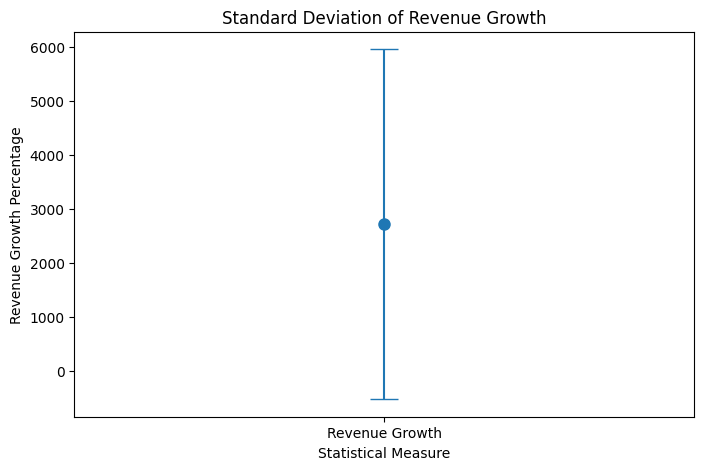

In [ ]:
# Calculate variance and standard deviation

# Variance and Standard Deviation

revenue_variance = df["Revenue_Growth_Percentage"].var()
revenue_std = df["Revenue_Growth_Percentage"].std()
mean_growth = df["Revenue_Growth_Percentage"].mean()

print("Revenue Growth Variance:", round(revenue_variance, 2))
print("Revenue Growth Standard Deviation:", round(revenue_std, 2))

# Error Bar Chart

plt.figure(figsize=(8, 5))

plt.errorbar(
    x=["Revenue Growth"],
    y=[mean_growth],
    yerr=[revenue_std],
    fmt="o",
    capsize=10,
    markersize=8
)

plt.title("Standard Deviation of Revenue Growth")
plt.xlabel("Statistical Measure")
plt.ylabel("Revenue Growth Percentage")

plt.show()

2. Variance and Standard Deviation –Interpretation

*   Revenue Growth Variance is approximately 10.5 million, indicating considerable variation in revenue growth percentages among companies.
*   Standard Deviation is approximately 3,230%, showing that company revenue growth rates are widely spread around the average.
*   The error bar chart indicates substantial variability in revenue growth, suggesting that companies have significantly different growth performances.
*   The large standard deviation indicates that some companies experience much higher or lower growth rates compared to the average.

**Key Insight:** Revenue growth varies considerably across companies, with a few exceptionally high-growth companies contributing to the large overall variation.

**Business Insight:** Businesses should investigate the factors contributing to differences in revenue growth and identify strategies that can help companies achieve more consistent and sustainable growth.

# Skewness, Kurtosis and Outlier Detection

we will analyse the shape of your company's revenue growth distribution to identify whether growth values are unevenly distributed and whether unusually high or low values may influence the results.

Let's start with skewness and kurtosis, then create a box plot to identify potential outliers. We'll keep each chart in a separate Google Colab cell and include a business interpretation.

Revenue Growth Skewness: 5.4
Revenue Growth Kurtosis: 41.13


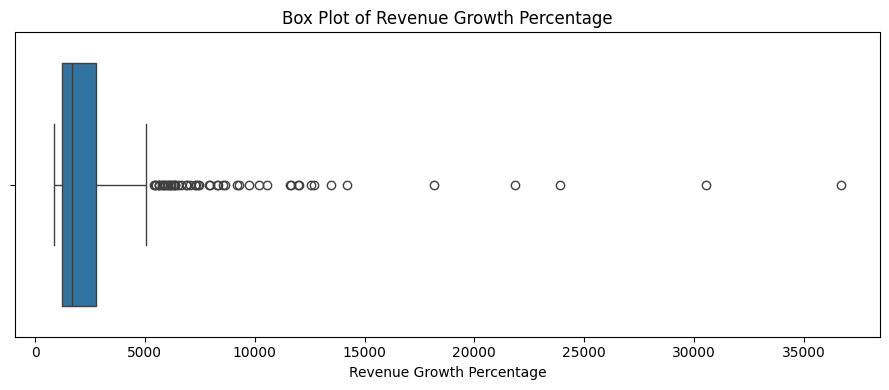

In [ ]:

growth = df["Revenue_Growth_Percentage"].dropna()

# Calculate Skewness and Kurtosis
skewness = growth.skew()
kurtosis = growth.kurt()

# Display Results
print("Revenue Growth Skewness:", round(skewness, 2))
print("Revenue Growth Kurtosis:", round(kurtosis, 2))


plt.figure(figsize=(9, 4))

sns.boxplot(x=df["Revenue_Growth_Percentage"])

# Add title and labels
plt.title("Box Plot of Revenue Growth Percentage")
plt.xlabel("Revenue Growth Percentage")

plt.tight_layout()
plt.show()

 Skewness, Kurtosis and Outlier Detection - Interpretation

*   Skewness of 5.40 indicates a strongly right-skewed revenue growth distribution, meaning most companies have comparatively lower growth rates, while a few companies experience exceptionally high growth.
*  Excess Kurtosis of 41.13 indicates a heavy-tailed distribution, suggesting the presence of extreme revenue growth values compared to a normal distribution.

*  ** Key Insight: **Revenue growth is highly uneven across companies. Most companies experience comparatively lower growth, while a small number achieve exceptionally high growth rates.

*   **Business Insight:** Businesses can investigate these high-growth companies to understand their growth strategies, market opportunities and performance factors. This may help identify successful business practices and support better growth planning.

# Univariate Analysis

Analysing Univariate Analysis, starting with a histogram showing the distribution of company revenue. Each chart will have its own code cell and a business-focused interpretation.

Univariate analysis examines one variable at a time to understand its distribution, frequency, and unusual values.

For your Company Growth and Workforce Analytics project, we'll begin with the distribution of revenue growth, then examine company size and workforce. Each chart will have a separate code cell and a business-focused interpretation.

1. Histogram — Distribution of Revenue Growth
This chart shows how many companies fall within different revenue growth ranges.

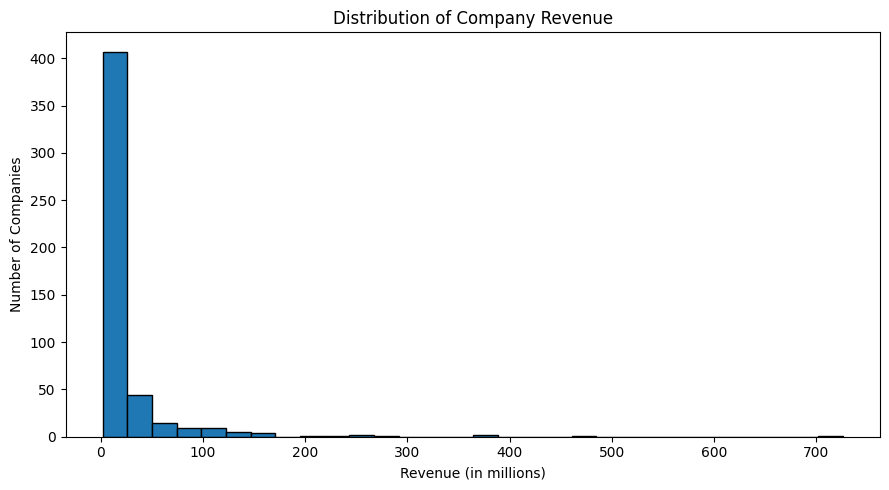

In [ ]:
# Histogram: Distribution of Company Revenue

plt.figure(figsize=(9, 5))

plt.hist(df["Revenue_in_millions"], bins=30, edgecolor="black")

plt.title("Distribution of Company Revenue")
plt.xlabel("Revenue (in millions)")
plt.ylabel("Number of Companies")

plt.tight_layout()
plt.show()

 – Revenue Distribution (Central Tendency) - Interpretation
*   The histogram shows the distribution of revenue among 502 companies. The average revenue (Mean) is approximately 24.37 million, while the median revenue is 8.05 million.
*   The mean is considerably higher than the median, indicating a right-skewed revenue distribution. This suggests that a relatively small number of companies with exceptionally high revenue increase the overall average.
*   Most companies operate at comparatively lower revenue levels, while a smaller group generates substantially higher revenue.
* This highlights the differences in business scale and revenue performance among the companies.

**Key Insight:** Revenue is unevenly distributed among the 502 companies, with a few high-revenue companies significantly influencing the overall average.

**Business Insight:** Companies should consider both mean and median revenue when comparing business performance. Median revenue provides a better understanding of the typical company's revenue level, while mean revenue reflects the overall average, including high-revenue companies.

2. Count plot — Distribution of Company Size

This chart compares the number of small, medium, and large companies in your dataset.

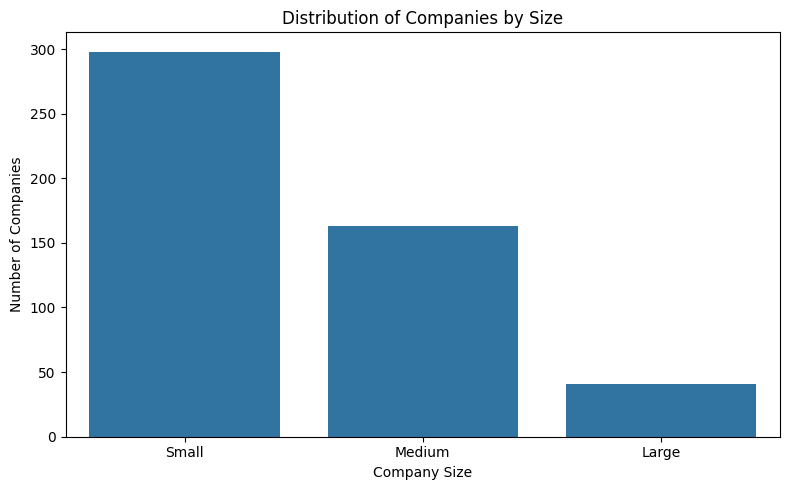

In [ ]:
# Count Plot: Company Size Distribution

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Company_Size")

plt.title("Distribution of Companies by Size")
plt.xlabel("Company Size")
plt.ylabel("Number of Companies")

plt.tight_layout()
plt.show()

3. Box plot — Distribution of Workforce Size

This chart helps identify the spread of employee counts and potential outliers among companies.

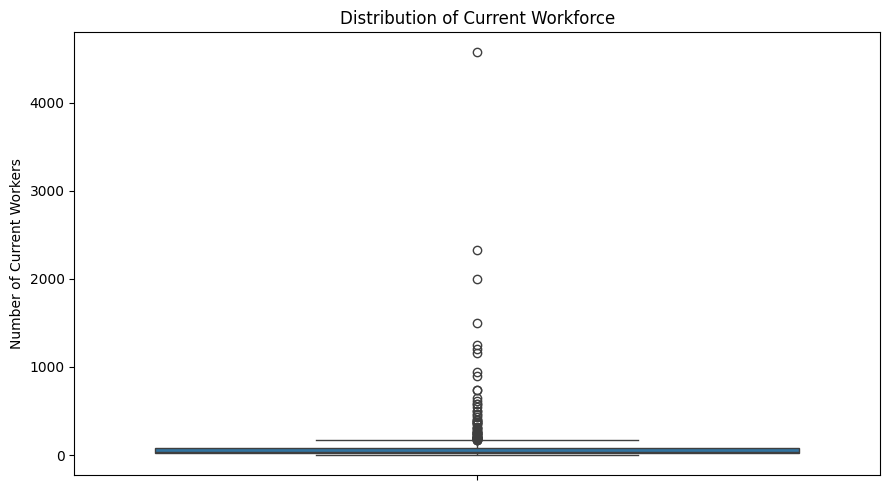

In [ ]:
# Box Plot: Current Workforce Distribution

plt.figure(figsize=(9,5))

sns.boxplot(y=df["Current_Workers"])

plt.title("Distribution of Current Workforce")
plt.ylabel("Number of Current Workers")

plt.tight_layout()
plt.show()

Workforce Distribution - Interpretation

*   The median workforce is 38 employees, while the average workforce is approximately 104 employees.
*    The higher average compared to the median indicates that a few companies with very large workforces increase the overall average.
*   The box plot highlights companies with unusually high workforce sizes compared to the majority.
*   List item

**Key Insight:** Most companies have relatively small workforces, while a few companies employ significantly more people.

**Business Insight:**This analysis helps understand the typical workforce size and identify companies operating on a much larger scale.

# Bivariate Analysis

Bivariate analysis studies the relationship between two variables. For your Company Growth and Workforce Analytics project, we'll examine whether revenue is related to revenue growth, compare industry performance, and investigate workforce growth.

Each chart below has its own separate Google Colab code cell, followed by a business-focused interpretation.

1. Scatter plot — Revenue vs Revenue Growth

Objective 5: Study Revenue and Growth Trends

This chart helps determine whether companies with higher revenue also tend to have higher revenue growth percentages.

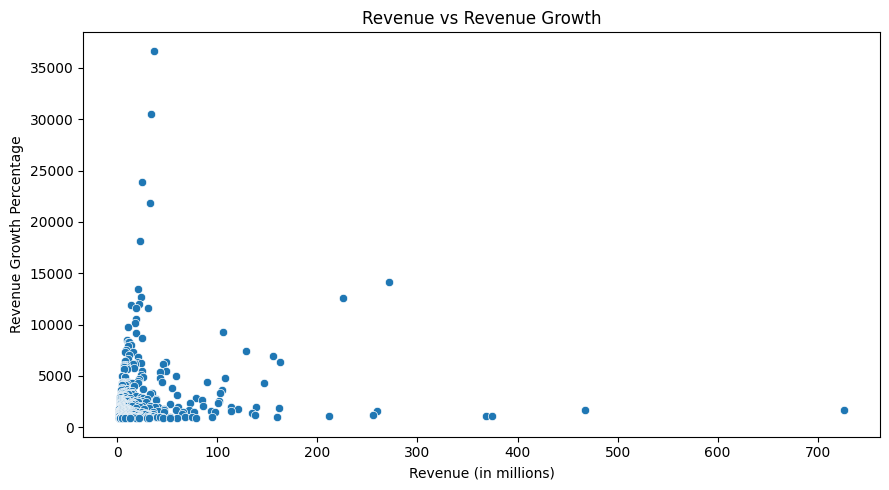

In [ ]:
# Scatter Plot: Revenue vs Revenue Growth

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Revenue_in_millions",
    y="Revenue_Growth_Percentage"
)

plt.title("Revenue vs Revenue Growth")
plt.xlabel("Revenue (in millions)")
plt.ylabel("Revenue Growth Percentage")

plt.tight_layout()
plt.show()


Relationship Between Revenue and Revenue Growth -Interpretation

- The scatter plot shows a very weak positive relationship between revenue and revenue growth, with a correlation of approximately 0.07.
- This indicates that companies with higher revenue do not necessarily achieve higher revenue growth.
- Companies with smaller revenues may also experience significant growth.

Key Insight: Revenue size has almost no linear relationship with revenue growth in this dataset.

Business Insight: Companies should not be judged by revenue alone. Both revenue size and growth percentage should be evaluated separately to identify high-performing businesses.

---



2. Bar plot — Total Revenue by Industry
Objective 2: Compare Industry Performance

This chart identifies the industries contributing the highest combined revenue in your dataset.

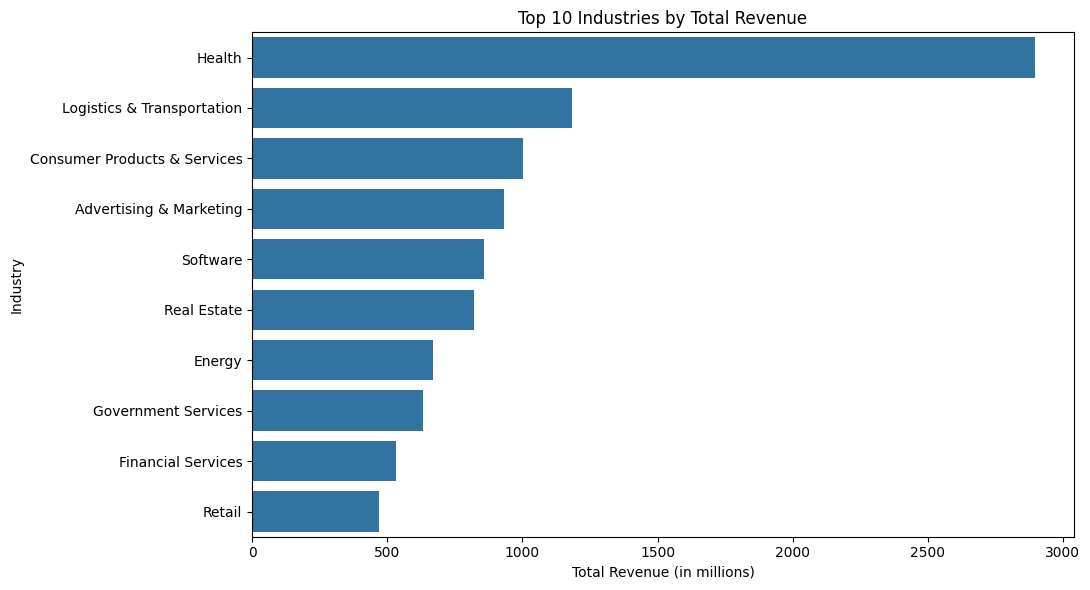

In [ ]:
# Bar Plot: Top 10 Industries by Total Revenue

industry_revenue = (
    df.groupby("Industry")["Revenue_in_millions"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=industry_revenue.values,
    y=industry_revenue.index
)

plt.title("Top 10 Industries by Total Revenue")
plt.xlabel("Total Revenue (in millions)")
plt.ylabel("Industry")

plt.tight_layout()
plt.show()

Industry Revenue Comparison-Interpretation:

- The Health industry generates the highest combined revenue at approximately 2,895.5 million, followed by Logistics & Transportation at 1,183.8 million.
- This shows that the Health industry makes the largest contribution to the total revenue among the industries analyzed.
- The difference in revenue highlights the varying business scales across industries.

Key Insight: The Health industry is the leading revenue-generating industry in the dataset.

Business Insight: Businesses can use this comparison to identify industries with strong revenue contributions and potential market opportunities. However, total revenue alone does not indicate profitability or the performance of individual companies.

3. Scatter plot — Current Workforce vs Employee Growth

Objective 3: Evaluate Workforce Growth

This chart explores whether companies with larger workforces also tend to have higher employee growth percentages.

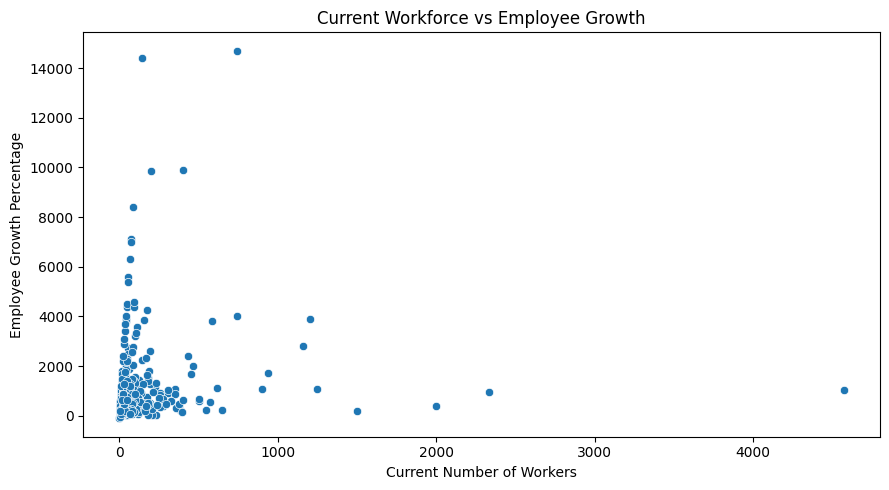

In [ ]:
# Scatter Plot: Workforce Size vs Employee Growth

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Current_Workers",
    y="Employee_Growth_Percentage"
)

plt.title("Current Workforce vs Employee Growth")
plt.xlabel("Current Number of Workers")
plt.ylabel("Employee Growth Percentage")

plt.tight_layout()
plt.show()

Relationship Between Workforce Size and Employee Growth - Interpretation

- The scatter plot shows a very weak positive relationship between current workforce size and employee growth percentage, with a correlation of approximately 0.03.
- This indicates that companies with larger workforces do not necessarily experience higher employee growth.
- Smaller companies may also achieve substantial workforce expansion.

Key Insight: Current workforce size has almost no linear relationship with employee growth
percentage in the dataset.

Business Insight: Businesses should evaluate workforce size and employee growth separately to understand company expansion and identify fast-growing companies, regardless of their current workforce size.

# Multivariate Analysis
Multivariate analysis examines three or more variables together to discover patterns and relationships in your company dataset.


1. Correlation heatmap — Company Performance

This chart examines relationships among revenue, revenue growth, workforce size, and employee growth.

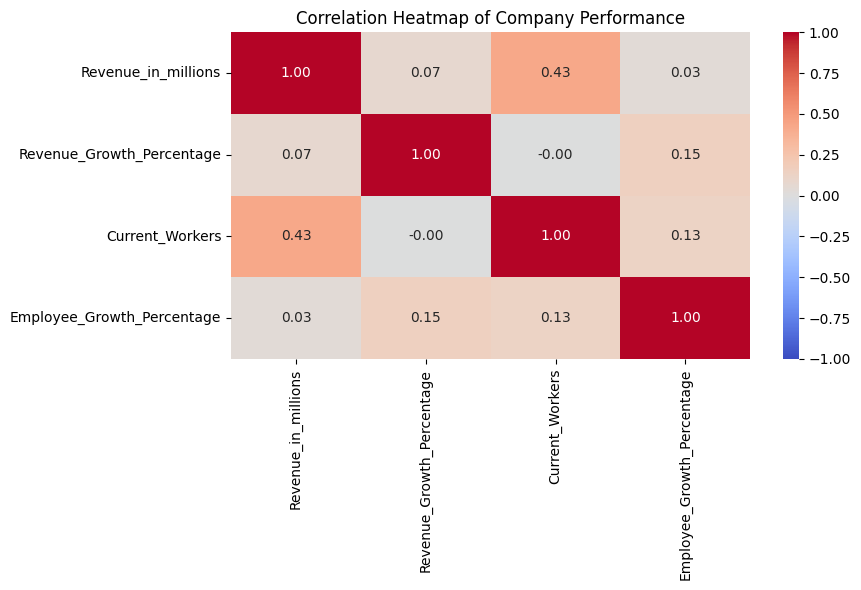

In [ ]:
# Correlation Heatmap of Company Performance

columns = [
    "Revenue_in_millions",
    "Revenue_Growth_Percentage",
    "Current_Workers",
    "Employee_Growth_Percentage"
]

correlation_data = df[columns].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Company Performance")
plt.tight_layout()
plt.show()

Correlation Between Business and Workforce Variables - Interpretation

- The heatmap shows the correlation between revenue, revenue growth, current workforce, and employee growth percentage.
- Correlation values range from −1 to +1. Positive values indicate variables tend to increase together, negative values indicate an inverse relationship, and values near zero indicate a weak linear relationship.
- Revenue and revenue growth have a very weak relationship. Similarly, current workforce size and employee growth percentage also show a very weak relationship.
- This indicates that higher-revenue companies do not necessarily grow faster, and companies with larger workforces do not necessarily expand their workforce more quickly.

Key Insight: Business size, measured by revenue or workforce, does not necessarily indicate higher growth performance.

Business Insight: Companies should evaluate revenue, revenue growth, workforce size, and employee growth separately to understand overall business performance and expansion trends.

2. Grouped analysis — Industry revenue and workforce

This chart compares two business measures across industries: total revenue and total current workforce.

,Total_Revenue,Total_Workers
Industry,,
Health,2895.5,11944
Logistics & Transportation,1183.8,2778
Consumer Products & Services,1003.9,2399
Advertising & Marketing,931.6,2981
Software,857.8,6127
Real Estate,822.5,1708
Energy,668.1,2255
Government Services,632.8,2557
Financial Services,531.7,2180


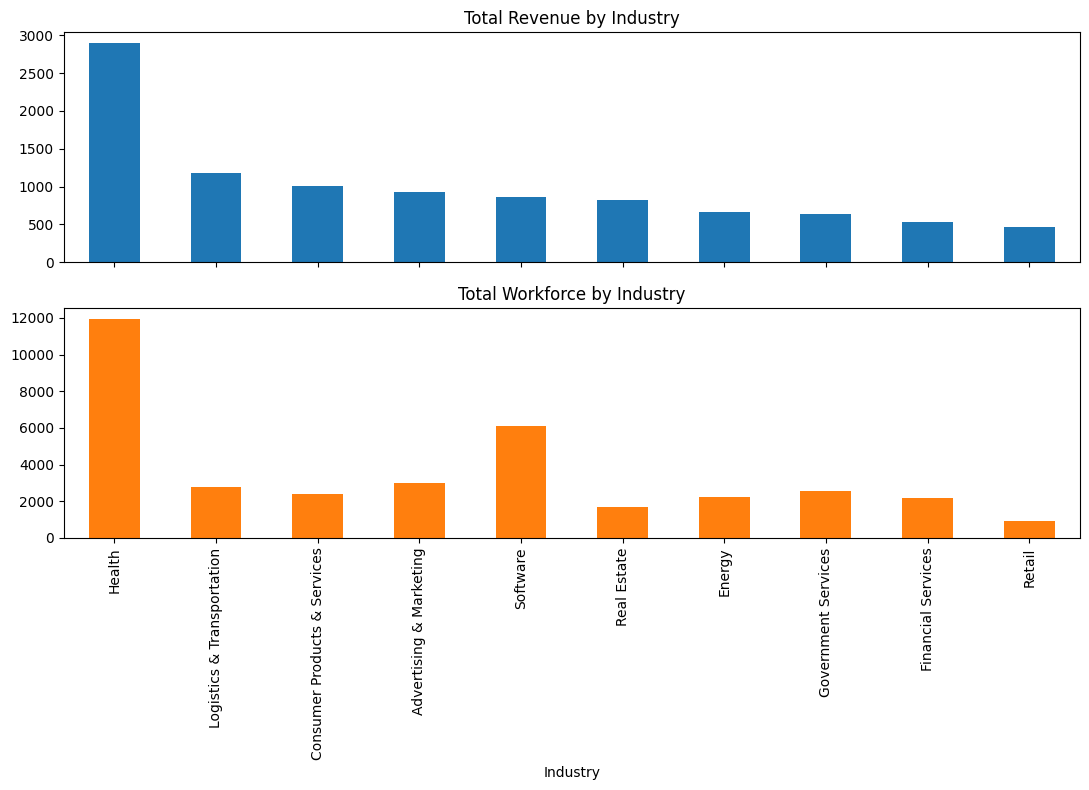

In [ ]:
# Group by industry and calculate total revenue and total current workers
industry_summary = (
    df.groupby("Industry")
    .agg(
        Total_Revenue=("Revenue_in_millions", "sum"),
        Total_Workers=("Current_Workers", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
    .head(10)
)

display(industry_summary)

industry_summary[["Total_Revenue", "Total_Workers"]].plot(
    kind="bar",
    subplots=True,
    figsize=(11, 8),
    legend=False,
    layout=(2, 1),
    title=["Total Revenue by Industry", "Total Workforce by Industry"]
)

plt.tight_layout()
plt.show()

Industry Revenue and Workforce Comparison -Interpretation

- The analysis compares the top 10 industries by total revenue and their combined workforce sizes.
- Industries with both high revenue and large workforces may operate on a larger business scale.
- Industries generating high revenue with fewer employees may be worth examining further to understand their revenue per employee.

Key Insight: Different industries contribute to business revenue and workforce size at different levels.

Business Insight: This comparison helps identify leading industries and areas for further productivity analysis. Revenue and workforce size should be considered together, but they do not directly establish profitability or employee productivity.

3. Revenue per employee — Workforce productivity

This analysis supports Objective 6 of your project. It compares revenue generated per employee across companies.

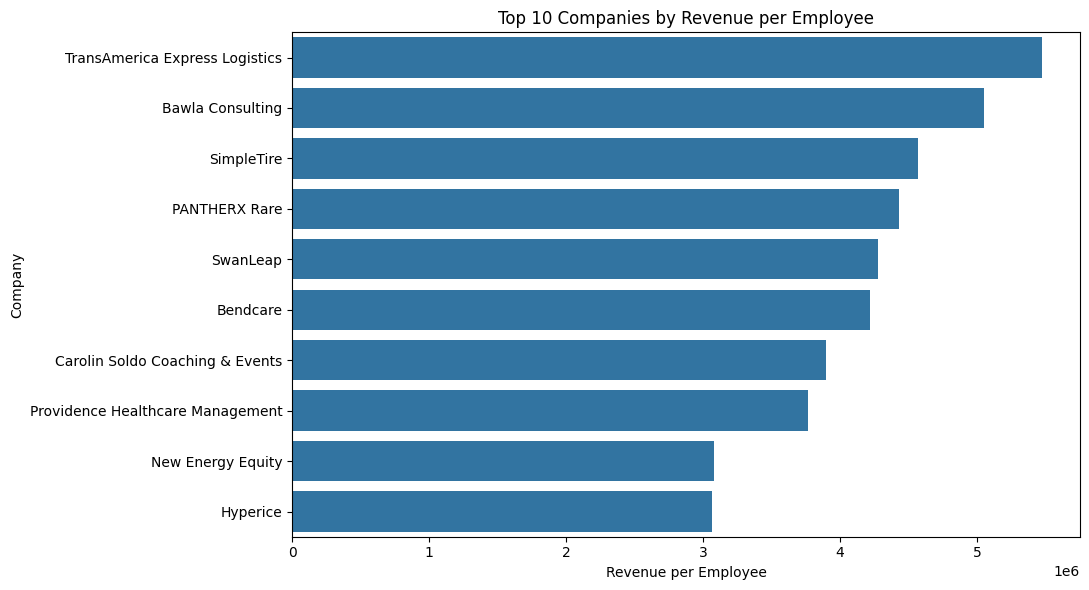

In [ ]:
df["Revenue_Per_Employee"] = (
    df["Revenue_in_millions"] * 1_000_000
    / df["Current_Workers"]
)

# Select the top 10 companies
top_productivity = (
    df[df["Current_Workers"] > 0]
    .nlargest(10, "Revenue_Per_Employee")
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_productivity,
    x="Revenue_Per_Employee",
    y="Company_name"
)

plt.title("Top 10 Companies by Revenue per Employee")
plt.xlabel("Revenue per Employee")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

Revenue per Employee Analysis -Interpretation

- The chart identifies the companies with the highest revenue per employee.
- A higher revenue-per-employee value indicates that a company generates more revenue relative to its current workforce.
- These companies may be operating with comparatively lean workforces and generating higher revenue per employee.
- However, revenue per employee does not directly measure profit or individual employee performance. Industry differences, outsourcing, and workforce reporting can also influence the results.

Key Insight: Some companies generate higher revenue with comparatively fewer employees.

Business Insight: Businesses can use this measure to compare revenue efficiency and identify companies for further productivity analysis. However, industry differences should be considered when making comparisons.

# Company Age and Business Trends

Objective 7: Study Company Age and Business Trends.

To analyze company founding years, compare newer and older companies, and identify which industries have the highest and lowest representation. Each visualization will have its own code cell and a business-focused interpretation.

1. Histogram — Distribution of Company Founding Years

This chart shows when companies in your dataset were founded and which periods have the most company representation.

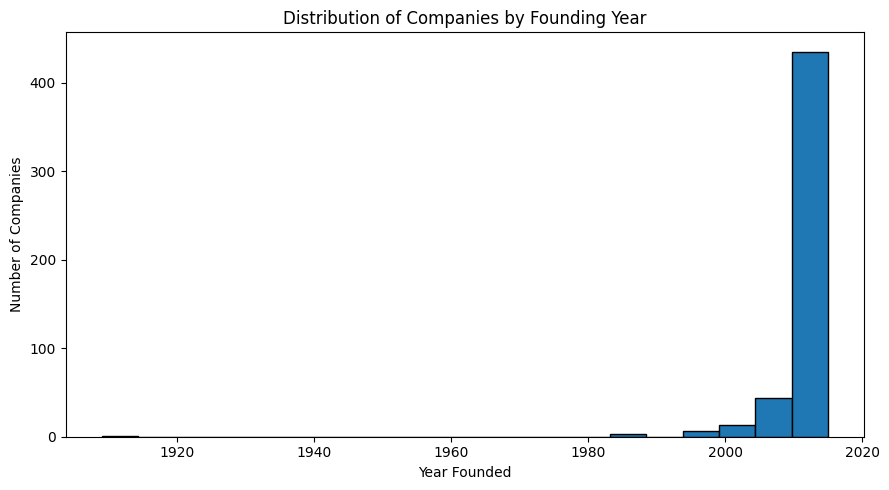

In [ ]:
# Histogram: Company Founding Years

plt.figure(figsize=(9, 5))

plt.hist(df["Founded"].dropna(), bins=20, edgecolor="black")

plt.title("Distribution of Companies by Founding Year")
plt.xlabel("Year Founded")
plt.ylabel("Number of Companies")

plt.tight_layout()
plt.show()

Company Founding Year Distribution -Interpretation

- The histogram shows the distribution of companies based on their founding years.
- It helps identify the periods in which most companies were established and whether the dataset contains more recently founded companies or older businesses.
- This analysis provides an overview of company age distribution and helps understand the background of the companies included in the dataset.

Key Insight: The founding-year distribution highlights how company representation varies across different periods.

Business Insight: Businesses can use this analysis as a starting point to compare newer and older companies and investigate whether company age is related to revenue growth and workforce expansion.

2. Bar chart — Average Revenue Growth by Company Age Group

This chart compares revenue growth among newer, middle-aged, and older companies.

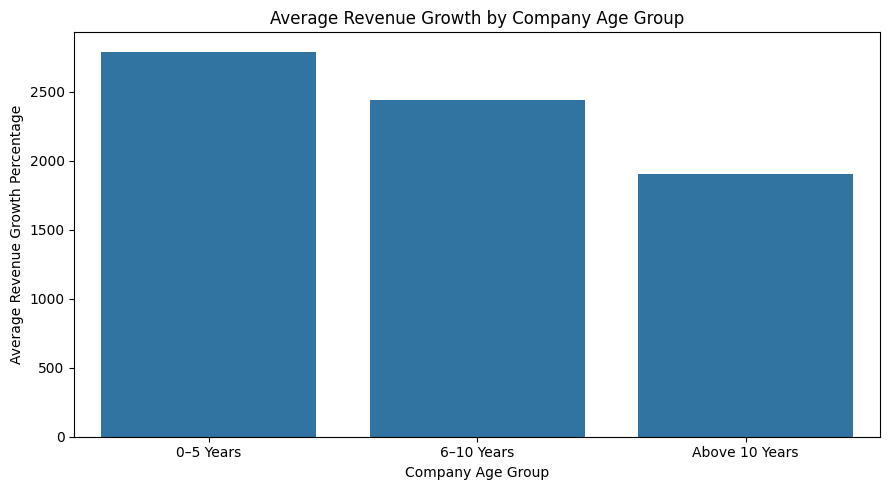

In [ ]:
# Group Companies by Age

df["Age_Group"] = pd.cut(
    df["Company_Age"],
    bins=[-1, 5, 10, 100],
    labels=["0–5 Years", "6–10 Years", "Above 10 Years"]
)

age_growth = (
    df.groupby("Age_Group", observed=False)["Revenue_Growth_Percentage"]
    .mean()
    .dropna()
)

plt.figure(figsize=(9, 5))

sns.barplot(x=age_growth.index, y=age_growth.values)

plt.title("Average Revenue Growth by Company Age Group")
plt.xlabel("Company Age Group")
plt.ylabel("Average Revenue Growth Percentage")

plt.tight_layout()
plt.show()

**Revenue Growth Across Company Age Groups -Interpretation**

- The chart compares the average revenue growth percentage of companies across different age groups.
- It helps identify whether newer companies or more established businesses have higher average revenue growth.
- A higher average growth rate in one age group may be influenced by a few companies with exceptionally high growth. Therefore, the median should also be considered to understand typical performance.

Key Insight: The comparison highlights differences in average revenue growth across company age groups.

Business Insight: Businesses can use this analysis to understand growth patterns among newer and older companies and identify which age groups show stronger growth performance.

3. Bar chart — Number of Companies by Industry

This chart identifies industries with the highest and lowest representation in the dataset.

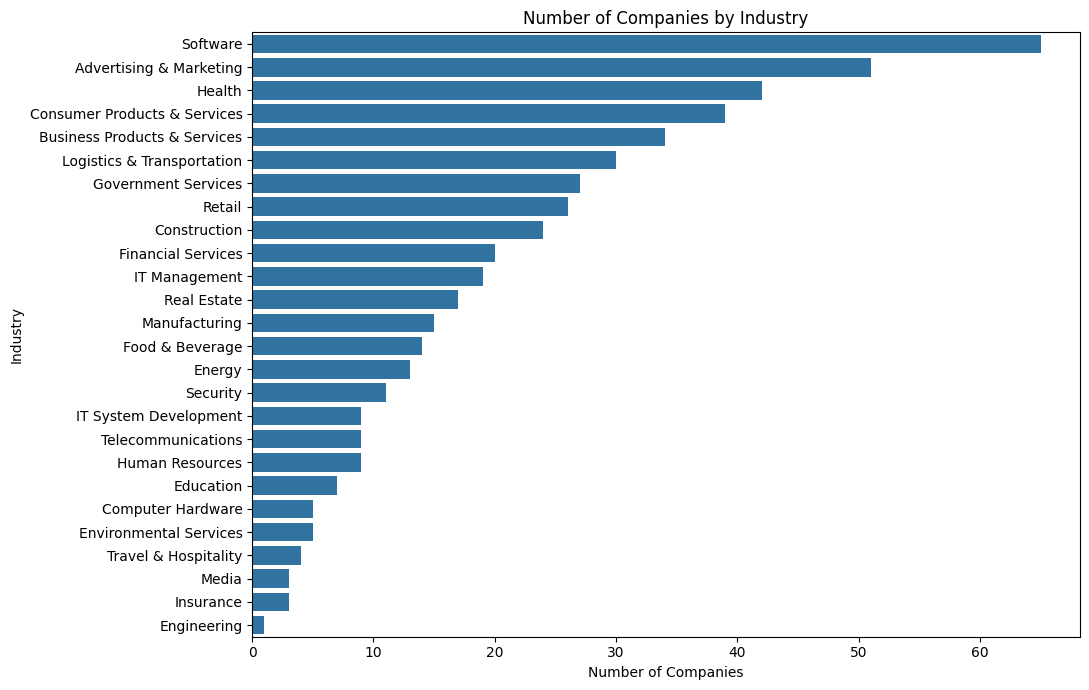

In [ ]:
# Number of Companies by Industry

industry_counts = df["Industry"].value_counts()

plt.figure(figsize=(11, 7))

sns.barplot(
    x=industry_counts.values,
    y=industry_counts.index
)

plt.title("Number of Companies by Industry")
plt.xlabel("Number of Companies")
plt.ylabel("Industry")

plt.tight_layout()
plt.show()


Industry Distribution -Interpretation

- The chart shows the distribution of 502 companies across different industries.
- Industries with longer bars have a higher number of companies, while shorter bars represent fewer companies.
- This helps identify which industries have the highest and lowest representation in the dataset.
- However, a higher number of companies in an industry does not necessarily mean higher revenue or faster business growth.

Key Insight: The dataset shows varying levels of company representation across different industries.

Business Insight: Businesses can use this analysis to identify the most represented industries and compare their revenue and growth performance to understand their overall business contribution.

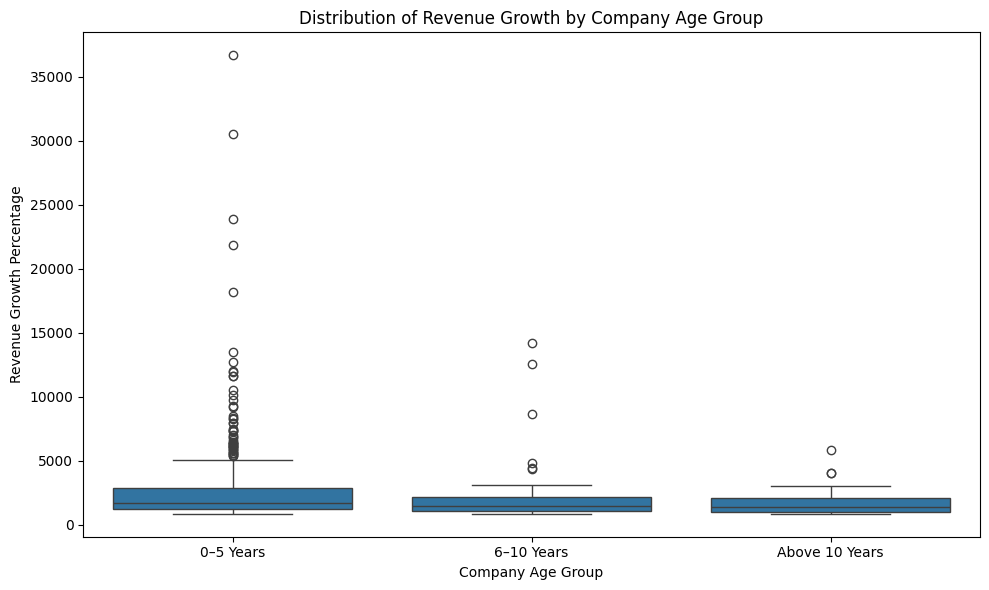

In [ ]:
# 4. Compare Revenue Growth by Age Group using a Box Plot
# This chart compares the spread of revenue growth, rather than just the average, across company age groups

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Age_Group",
    y="Revenue_Growth_Percentage"
)

plt.title("Distribution of Revenue Growth by Company Age Group")
plt.xlabel("Company Age Group")
plt.ylabel("Revenue Growth Percentage")

plt.tight_layout()
plt.show()

Revenue Growth Across Company Age Groups-Interpretation

- The box plot compares revenue growth percentages across different company age groups.
- Differences in the median lines show how typical revenue growth varies between age groups.
- The height of each box indicates the variation in growth rates within each group.
- Individual outliers may represent companies with exceptionally high or low growth and should be investigated rather than automatically removed.

Key Insight: Revenue growth and its variability differ across company age groups.

Business Insight: Businesses can use this comparison to understand growth patterns among newer and more established companies and identify unusual growth performance for further investigation.

Objective 4: Analyze Geographical Distribution

 To analyze where companies are located and compare their business performance by location.

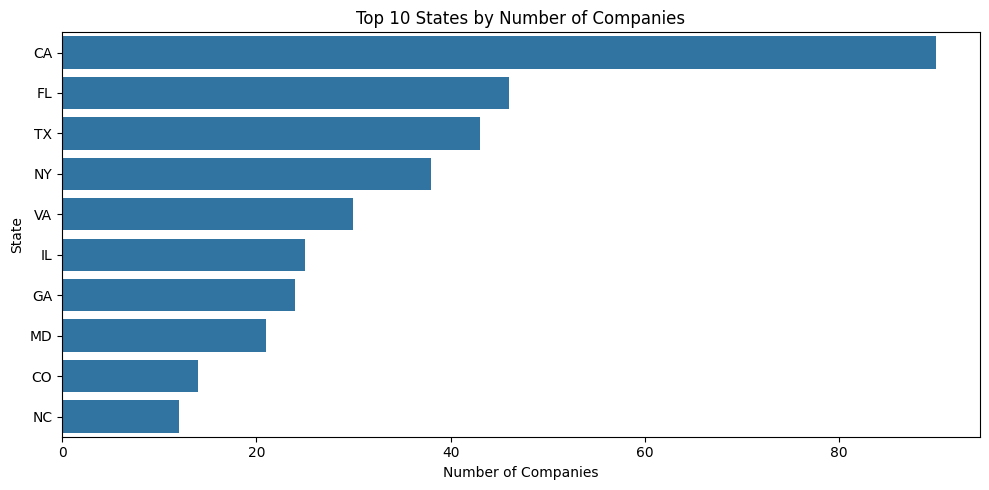

In [ ]:
# 1. Find the top 10 states by number of companies

state_counts = df["state"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=state_counts.values, y=state_counts.index)

plt.title("Top 10 States by Number of Companies")
plt.xlabel("Number of Companies")
plt.ylabel("State")
plt.tight_layout()
plt.show()

Company Distribution Across States -Interpretation

- California (CA) has the highest number of companies, with approximately 90 companies, making it the leading state in the dataset.
- Florida (FL) and Texas (TX) follow with around 46 and 43 companies, respectively, while New York (NY) ranks fourth with approximately 38 companies.
- Virginia, Illinois, Georgia, and Maryland show a moderate company presence, whereas Colorado and North Carolina have fewer companies among the top 10 states.
- Overall, the distribution indicates that companies are concentrated in a few leading states, particularly California.

Key Insight: California has the strongest company representation, followed by Florida, Texas, and New York.

Business Insight: This analysis highlights the major business locations in the dataset and helps identify states with a strong concentration of companies for further geographical and business performance analysis.

In [ ]:
# 2. Find the top 10 cities by number of companies

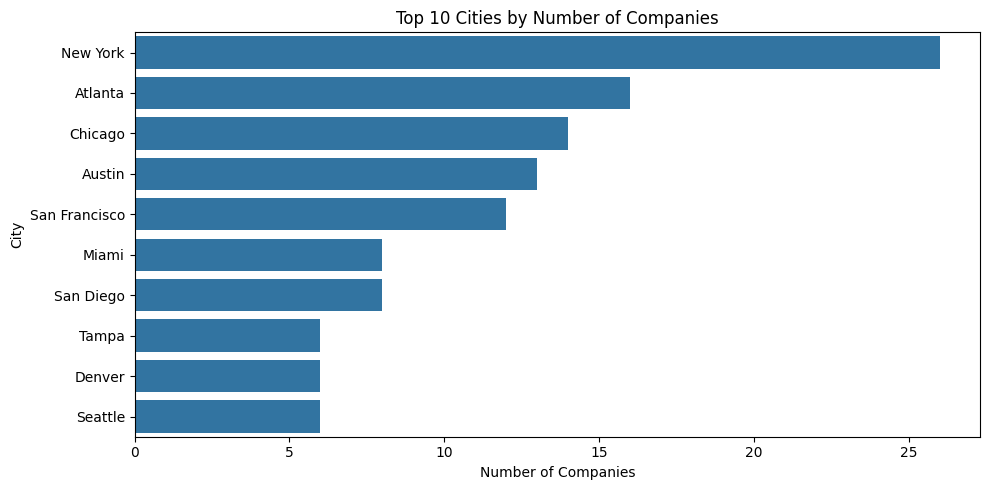

In [ ]:
city_counts = df["city"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=city_counts.values, y=city_counts.index)

plt.title("Top 10 Cities by Number of Companies")
plt.xlabel("Number of Companies")
plt.ylabel("City")
plt.tight_layout()
plt.show()

City-wise Distribution of Companies -Interpretation

- New York has the highest number of companies, with approximately 26 companies, making it the leading city in the dataset.
- Atlanta ranks second with around 16 companies, followed by Chicago (14) and Austin (13).
- San Francisco has approximately 12 companies, while Miami and San Diego each have around 8 companies.
- Tampa has no visible bar, indicating that it may have zero or very few companies in the dataset.

Key Insight: Company presence is concentrated in a few major cities, particularly New York and Atlanta, while the remaining cities have comparatively fewer companies.

Business Insight: This analysis helps identify major business locations and areas with a strong concentration of companies, which can support decisions about market expansion and regional business opportunities.

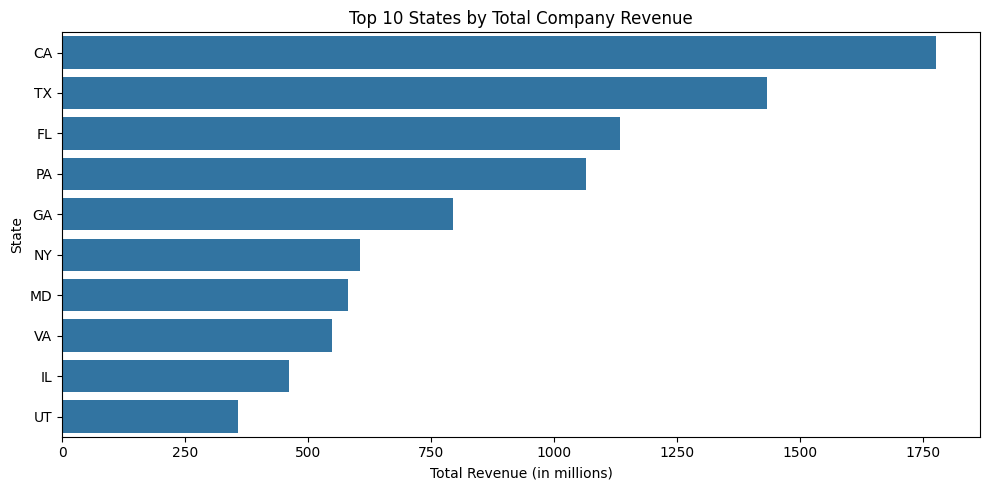

In [ ]:
# 3. Compare total revenue across states
state_revenue = (
    df.groupby("state")["Revenue_in_millions"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=state_revenue.values, y=state_revenue.index)

plt.title("Top 10 States by Total Company Revenue")
plt.xlabel("Total Revenue (in millions)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

State-wise Revenue Distribution-Interpretation

- California (CA) generates the highest total company revenue, approximately 1,775 million, making it the leading state among the top 10.
- Texas (TX) ranks second with around 1,435 million, followed by Florida (FL) at approximately 1,135 million and Pennsylvania (PA) at 1,065 million.
- Georgia (GA) contributes around 795 million, while New York (NY), Maryland (MD), and Virginia (VA) generate comparatively lower revenues.
- Illinois (IL) and Utah (UT) rank among the lowest in total revenue within this group.

Key Insight: California leads in both the number of companies and total revenue, indicating a strong business presence in the dataset. However, a higher number of companies does not always result in higher total revenue, as company size and individual performance also influence revenue.

Business Insight: This analysis helps identify states with strong revenue contributions and business activity. It can support decisions about regional market opportunities and help identify locations for potential business expansion.

In [ ]:
# Calculate necessary variables locally to ensure successful execution
state_counts = df["state"].value_counts().head(10)
city_counts = df["city"].value_counts().head(10)
state_revenue = (
    df.groupby("state")["Revenue_in_millions"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Display the results as tables
print("Top 10 States by Number of Companies")
display(state_counts.reset_index(name="Number_of_Companies"))

print("\nTop 10 Cities by Number of Companies")
display(city_counts.reset_index(name="Number_of_Companies"))

print("\nTop 10 States by Total Revenue")
display(state_revenue.reset_index(name="Total_Revenue_in_Millions"))

Top 10 States by Number of Companies


,state,Number_of_Companies
0,CA,90
1,FL,46
2,TX,43
3,NY,38
4,VA,30
5,IL,25
6,GA,24
7,MD,21
8,CO,14
9,NC,12



Top 10 Cities by Number of Companies


,city,Number_of_Companies
0,New York,26
1,Atlanta,16
2,Chicago,14
3,Austin,13
4,San Francisco,12
5,Miami,8
6,San Diego,8
7,Tampa,6
8,Denver,6
9,Seattle,6



Top 10 States by Total Revenue


,state,Total_Revenue_in_Millions
0,CA,1777.8
1,TX,1433.2
2,FL,1135.3
3,PA,1066.4
4,GA,794.1
5,NY,606.2
6,MD,582.4
7,VA,548.1
8,IL,461.6
9,UT,358.3


In [ ]:
# ==========================================
# BUSINESS INSIGHTS - COMPANY GROWTH ANALYSIS
# ==========================================

# Function to find the available column name
def find_column(possible_names):
    for col in possible_names:
        if col in df.columns:
            return col
    return None

# Identify dataset columns
company = find_column(["Company_name"])
revenue = find_column(["Revenue_in_millions"])
growth = find_column(["Revenue_Growth_Percentage"])
industry = find_column(["Industry", "domain", "Domain"])
state = find_column(["state", "State"])
city = find_column(["city", "City"])
workers = find_column(["Current_Workers"])
employee_growth = find_column(["Employee_Growth_Percentage"])
employee_change = find_column(["Employee_Change"])
company_age = find_column(["Company_Age"])
revenue_employee = find_column(["Revenue_Per_Employee"])

print("=" * 60)
print(" MNC GROWTH AND WORKFORCE BUSINESS INSIGHTS")
print("=" * 60)


# OBJECTIVE 1: COMPANY GROWTH
print("\n1. COMPANY GROWTH")

if company and growth:
    top = df.loc[df[growth].idxmax()]
    print("Highest revenue growth company:", top[company])
    print("Revenue growth percentage:", round(top[growth], 2), "%")

    print("Business Insight: This company has the highest recorded")
    print("revenue growth and can be studied to understand its growth pattern.")


# OBJECTIVE 2: INDUSTRY PERFORMANCE
print("\n2. INDUSTRY PERFORMANCE")

if industry and revenue:
    industry_revenue = df.groupby(industry)[revenue].sum().sort_values(ascending=False)

    print("Highest revenue industry:", industry_revenue.index[0])
    print("Total revenue:", round(industry_revenue.iloc[0], 2), "million")

    print("Business Insight: The leading industry contributes the")
    print("highest total revenue in the dataset.")

if industry and workers:
    industry_workers = df.groupby(industry)[workers].sum().sort_values(ascending=False)

    print("Largest workforce industry:", industry_workers.index[0])
    print("Total workforce:", industry_workers.iloc[0])


# OBJECTIVE 3: WORKFORCE GROWTH
print("\n3. WORKFORCE GROWTH")

if company and employee_growth:
    top = df.loc[df[employee_growth].idxmax()]
    print("Highest employee growth company:", top[company])
    print("Employee growth:", round(top[employee_growth], 2), "%")

    print("Business Insight: This company recorded the highest")
    print("employee growth percentage and may provide insights")
    print("into workforce expansion patterns.")

if workers and employee_growth:
    corr = df[workers].corr(df[employee_growth])
    print("Workforce size vs employee growth correlation:", round(corr, 2))


# OBJECTIVE 4: GEOGRAPHICAL DISTRIBUTION
print("\n4. GEOGRAPHICAL DISTRIBUTION")

if state:
    state_count = df[state].value_counts()
    print("State with the highest number of companies:", state_count.index[0])
    print("Number of companies:", state_count.iloc[0])

if city:
    city_count = df[city].value_counts()
    print("City with the highest number of companies:", city_count.index[0])
    print("Number of companies:", city_count.iloc[0])

if state and revenue:
    state_revenue_sum = df.groupby(state)[revenue].sum().sort_values(ascending=False)
    print("Highest revenue state:", state_revenue_sum.index[0])
    print("Total revenue:", round(state_revenue_sum.iloc[0], 2), "million")

    print("Business Insight: These locations have the strongest")
    print("company presence or revenue contribution in the dataset.")


# OBJECTIVE 5: REVENUE AND GROWTH TRENDS
print("\n5. REVENUE AND GROWTH TRENDS")

if revenue and growth:
    corr = df[revenue].corr(df[growth])
    print("Revenue vs revenue growth correlation:", round(corr, 2))

    if corr > 0.5:
        print("Business Insight: Revenue and growth have a strong positive relationship.")
    elif corr > 0:
        print("Business Insight: Revenue and growth have a weak positive relationship.")
    elif corr < -0.5:
        print("Business Insight: Revenue and growth have a strong negative relationship.")
    elif corr < 0:
        print("Business Insight: Revenue and growth have a weak negative relationship.")
    else:
        print("Business Insight: No linear relationship was identified.")


# OBJECTIVE 6: REVENUE PER EMPLOYEE
print("\n6. REVENUE PER EMPLOYEE")

if company and revenue_employee:
    valid = df.dropna(subset=[revenue_employee])
    valid = valid[valid[revenue_employee] > 0]

    if not valid.empty:
        top = valid.loc[valid[revenue_employee].idxmax()]
        print("Highest revenue per employee company:", top[company])
        print("Revenue per employee:", round(top[revenue_employee], 2))

        print("Business Insight: This company generates the highest")
        print("revenue relative to its recorded workforce.")


# OBJECTIVE 7: COMPANY AGE AND BUSINESS TRENDS
print("\n7. COMPANY AGE AND BUSINESS TRENDS")

if company_age:
    print("Average company age:", round(df[company_age].mean(), 2), "years")
    print("Youngest company age:", df[company_age].min(), "years")
    print("Oldest company age:", df[company_age].max(), "years")

if industry:
    print("\nIndustry with the highest company representation:")
    industry_count = df[industry].value_counts()
    print(industry_count.index[0], "-", industry_count.iloc[0], "companies")

if company_age and growth:
    age_growth = df.groupby(company_age)[growth].median()
    print("\nMedian revenue growth by company age:")
    print(age_growth)

print("\n" + "=" * 60)
print("           BUSINESS INSIGHTS ANALYSIS COMPLETED")
print("=" * 60)

       COMPANY GROWTH AND WORKFORCE BUSINESS INSIGHTS

1. COMPANY GROWTH
Highest revenue growth company: Freestar
Revenue growth percentage: 36680.39 %
Business Insight: This company has the highest recorded
revenue growth and can be studied to understand its growth pattern.

2. INDUSTRY PERFORMANCE
Highest revenue industry: Health
Total revenue: 2895.5 million
Business Insight: The leading industry contributes the
highest total revenue in the dataset.
Largest workforce industry: Health
Total workforce: 11944

3. WORKFORCE GROWTH
Highest employee growth company: SkillSet Group
Employee growth: 14700.0 %
Business Insight: This company recorded the highest
employee growth percentage and may provide insights
into workforce expansion patterns.
Workforce size vs employee growth correlation: 0.13

4. GEOGRAPHICAL DISTRIBUTION
State with the highest number of companies: CA
Number of companies: 90
City with the highest number of companies: New York
Number of companies: 26
Highest revenue state

**8. Objective-wise Business Analysis and Insights**

 This section presents the key findings from the seven project objectives. The analysis uses company revenue, revenue growth, workforce details, industry, geographical location, and company age to understand business performance and growth patterns.

# Objective 1: Analyze Company Growth

Purpose: To identify companies with the highest revenue growth percentage and understand their growth performance.

Key Findings:
- The analysis identified companies with the highest revenue growth percentages.
- Revenue growth is highly right-skewed, with a skewness value of approximately 5.40.
- A few companies show exceptionally high growth rates, while most companies have comparatively lower growth.
- The presence of extreme values indicates that company growth is not evenly distributed.
Key Insight: A small number of companies experience exceptionally high revenue growth, while most companies show comparatively moderate growth.

Business Insight: Businesses can study high-growth companies to understand their growth strategies and identify potential market opportunities.

# Objective 2: Compare Industry Performance

Purpose: To identify which industries generate the highest total revenue and have the largest workforce.

Key Findings:
- The Health industry generates the highest total revenue, approximately 2,895.5 million.
- Logistics & Transportation ranks second, with approximately 1,183.8 million in total revenue.
- The analysis compared the top 10 industries based on their total revenue and workforce.
- Revenue and workforce contributions vary across industries.

Key Insight: The Health industry contributes the highest total revenue among the industries in the dataset.

Business Insight: Identifying high-revenue industries helps businesses understand important market sectors and explore potential growth opportunities. Comparing revenue and workforce also helps identify areas for further productivity analysis.

# Objective 3: Evaluate Workforce Growth

Purpose: To identify companies with the highest employee growth compared to their previous workforce.

Key Findings:
- Employee change and employee growth percentage were calculated using previous and current workforce figures.
- Companies were compared based on their employee growth percentages.
- The correlation between current workforce size and employee growth percentage is approximately 0.03, indicating a very weak positive relationship.
- A company with a large workforce does not necessarily experience higher employee growth.

Key Insight: Workforce size has almost no linear relationship with employee growth percentage.

Business Insight: Businesses should evaluate workforce size and employee expansion separately to understand hiring patterns and identify companies experiencing rapid workforce growth.

# Objective 4: Analyze Geographical Distribution

Purpose: To identify the states and cities with the highest number of companies and compare business performance by location.

Key Findings:
- California has the highest number of companies, with approximately 90 companies.
- Florida, Texas, and New York follow with approximately 46, 43, and 38 companies, respectively.
- New York City has the highest city-wise company count, with approximately 26 companies, followed by Atlanta with around 16.
- California generates the highest total revenue among the top 10 states, with approximately 1,775 million.
- Texas ranks second in total revenue, contributing around 1,435 million.

Key Insight: California leads in both company representation and total revenue, while New York leads in the city-wise distribution of companies.

Business Insight: Geographical analysis helps identify major business locations and regions with strong company presence and revenue contribution. This information can support regional market expansion decisions.

# Objective 5: Study Revenue and Growth Trends

Purpose: To analyze the relationship between company revenue and revenue growth percentage.

Key Findings:
- A scatter plot and correlation analysis were used to examine the relationship between revenue and revenue growth percentage.
- The correlation value is approximately 0.07, indicating a very weak positive relationship.
- Companies with higher revenue do not necessarily have higher revenue growth.
- Smaller companies can also experience high revenue growth percentages.

Key Insight: Company revenue and revenue growth percentage have almost no linear relationship in the dataset.

Business Insight: Businesses should evaluate revenue generation and growth performance separately rather than assuming that companies with higher revenue will always grow faster.

# Objective 6: Analyze Revenue per Employee

Purpose: To identify companies with the highest revenue per employee and evaluate workforce productivity.

Key Findings:
- Revenue per employee was calculated by comparing company revenue with its current workforce.
- Companies were compared to identify those generating higher revenue relative to their employee count.
- Some companies generate comparatively higher revenue with fewer employees.
- Revenue per employee provides an indication of revenue efficiency, but it does not directly measure profit or individual employee performance.

Key Insight: Some companies generate higher revenue relative to their workforce size, indicating differences in revenue efficiency.

Business Insight: Revenue per employee helps businesses compare how effectively companies generate revenue in relation to their workforce. Industry differences and outsourcing practices should also be considered when making comparisons.

# Objective 7: Study Company Age and Business Trends

Purpose: To study company distribution across founding years, compare newer and older companies, and identify industry representation.

Key Findings:
- Companies were analyzed based on their founding years to understand their age distribution.
- Company age was calculated using 2015 as the reference year, since the dataset ends in 2015.
- Revenue growth was compared across different company age groups.
- Box plots were used to compare growth distribution and identify unusually high or low values.
- Industry distribution showed differences in the number of companies represented across industries.

Key Insight: Revenue growth patterns and company representation vary across company age groups and industries.

Business Insight: Comparing newer and older companies helps businesses understand growth patterns at different stages of development. Industry distribution also highlights sectors with higher and lower company representation.

# Documentation, Insights & Presentation

This section summarizes the major findings of the Company Growth and Workforce Analytics project. It explains the key business insights, different types of analysis, and recommendations that can support better business decision-making.

# Summary Of Key Findings

1. Company Growth
- Freestar recorded the highest revenue growth of 36,680.39%.
- Average revenue growth was 2,717.96%, while the median was 1,701.41%.
- Skewness was 5.40, indicating that a few companies experienced exceptionally high growth compared with most companies.
2. Industry Performance
- Health was the highest revenue-generating industry, with total revenue of 2,895.5 million.
- It also had the largest workforce, with 11,944 employees.
- Logistics & Transportation ranked second in revenue, generating 1,183.8 million.
3. Workforce Growth
- SkillSet Group recorded the highest employee growth percentage at 14,700%.
- The correlation between current workforce size and employee growth was approximately 0.13 in the final business-insights calculation, indicating a very weak positive relationship.
- This means companies with larger workforces do not necessarily experience faster employee growth.
4. Geographical Distribution
- California had the highest number of companies, with 90 companies.
- Florida ranked second with 46, followed by Texas with 43 and New York with 38.
- New York City had the highest city-wise count, with 26 companies.
- California also generated the highest state-wise revenue at $1,777.8 million, followed by Texas at $1,433.2 million.
5. Revenue and Growth Relationship
- The correlation between revenue and revenue growth was approximately 0.07.
- This indicates a very weak positive relationship.
- Higher-revenue companies do not necessarily experience higher revenue growth.
6. Revenue per Employee
- Revenue per employee was calculated to compare revenue generated relative to the number of employees.
- The analysis identified differences in revenue efficiency among companies.
- Some companies generated comparatively higher revenue with fewer employees. However, this measure does not directly indicate profit or individual employee productivity.
7. Company Age and Business Trends
- Average company age was approximately 2.97 years.
- The youngest company was 0 years old, while the oldest was 106 years old.
- Revenue growth was compared across three age groups: 0–5 years, 6–10 years, and above 10 years.

Important overall conclusions
1. The Health industry leads in both total revenue and workforce size.
2. California is the strongest state in terms of company count and total revenue.
3. Revenue and workforce size do not necessarily determine growth performance.
4. Revenue is unevenly distributed, with a few high-revenue companies influencing the average.
5. Revenue per employee provides a useful way to compare revenue efficiency.

# Key Insights

1. Company Growth: Revenue growth varies significantly across companies, with a few businesses showing exceptionally high growth percentages.

2. Industry Performance: The Health industry contributes the highest total revenue, indicating its strong revenue contribution within the dataset.

3. Workforce Analysis: Most companies have relatively small workforces, and larger companies do not necessarily experience faster employee growth.

4. Geographical Distribution: California leads in both company count and total revenue, highlighting its strong business presence in the dataset.

5. Revenue and Growth Relationship: Revenue and revenue growth have a very weak positive correlation of approximately 0.07, showing that higher-revenue companies do not necessarily grow faster.

Types of Analysis

1. Descriptive Analysis

 Meaning: Descriptive analysis explains what has happened in the dataset by summarizing and presenting the available data.

Analysis Performed and Key Findings:
- Calculated mean, median, variance, and standard deviation to understand company revenue and growth patterns.
- Analyzed revenue and workforce distribution. The average company revenue was approximately 24.37 million, while the median was 8.05 million.
- Categorized companies based on workforce size: 298 Small, 163 Medium, and 41 Large companies, out of 502 companies.
- Compared industry-wise revenue and found that the Health industry generated the highest total revenue of approximately 2,895.5 million.
- Analyzed geographical distribution and found that California had the highest number of companies (90), while New York City had the highest city-wise count (26).
- Used histograms, count plots, box plots, and bar charts to present the findings.
Outcome: Descriptive analysis provided an overall understanding of company revenue, growth, workforce distribution, industry performance, and geographical presence. It showed that most companies in the dataset belong to the Small category.

2. Diagnostic Analysis

  Meaning: Diagnostic analysis examines relationships between variables to understand why certain patterns or results occur.

Analysis Performed and Key Findings:
- Examined the relationship between company revenue and revenue growth using scatter plots and correlation analysis. The correlation was approximately 0.07, indicating a very weak positive relationship.
- Compared current workforce size with employee growth percentage. The correlation was approximately 0.03, showing almost no linear relationship.
- Analyzed employee growth and found that SkillSet Group recorded the highest employee growth of 14,700%.
- Compared industry-wise revenue and workforce contributions to understand differences in business scale.
- Studied revenue growth across different company age groups using visualizations.
Outcome: Diagnostic analysis showed that higher company revenue does not necessarily mean higher revenue growth, and companies with larger workforces do not necessarily experience faster employee growth. Revenue and workforce performance should therefore be evaluated separately.

3. Predictive Analysis

  Meaning: Predictive analysis uses historical data, statistical methods, or machine learning models to estimate possible future outcomes.

Future Scope for This Project:
- Develop regression models to predict future company revenue.
- Estimate future workforce growth based on employee trends.
- Identify companies that may experience higher revenue or employee growth.
- Apply machine learning techniques to forecast business performance.
Outcome: Predictive analysis was not performed in the current project. However, it could be included in future work to estimate company performance and support business forecasting.

4. Prescriptive Analysis

  Meaning: Prescriptive analysis recommends possible actions based on analytical findings to support business decision-making.

Recommendations Based on Project Findings:
- Explore industries such as Health, which generated the highest total revenue of approximately $2,895.5 million.
- Consider locations such as California, which had the highest company count of 90 and the highest total revenue among the top 10 states.
- Improve workforce planning by evaluating employee growth separately from current workforce size.
- Compare revenue per employee to understand how efficiently companies generate revenue relative to their workforce.
- Study high-growth companies to understand their business growth patterns.
Outcome: Specific optimization or recommendation models were not developed in the current project. However, the findings provide useful business insights that can support decisions related to industry opportunities, geographical expansion, workforce planning, and revenue efficiency.

# Future Enhancements and Suggestions

Future Enhancements and Suggestions
1. Use updated company data to study recent business growth and workforce trends.
2. Include more companies and additional details such as profit, expenses, and investments.
3. Apply advanced statistical and machine learning techniques to predict future company growth.
4. Develop an interactive dashboard using Power BI or Tableau to present business insights.
5. Improve geographical and industry-wise analysis to identify business opportunities and expansion possibilities.

In [ ]:
# Export the cleaned and transformed dataset

df.to_csv("Modified_Company_Growth_Dataset.csv", index=False)

print("Cleaned dataset exported successfully!")

# Download all exported files

from google.colab import files

files.download("Modified_Company_Growth_Dataset.csv")

Cleaned dataset exported successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import zipfile
from google.colab import files

# Ensure the export directory exists
os.makedirs("Project_Results", exist_ok=True)

# Compute top 10 datasets and statistics dynamically to prevent NameError
top_growth = df.nlargest(10, "Revenue_Growth_Percentage")[["Company_name", "Revenue_Growth_Percentage", "Revenue_in_millions"]]
industry_revenue_df = df.groupby("Industry")["Revenue_in_millions"].sum().sort_values(ascending=False)
industry_workforce_df = df.groupby("Industry")["Current_Workers"].sum().sort_values(ascending=False)
top_employee_growth = df.nlargest(10, "Employee_Growth_Percentage")[["Company_name", "Employee_Growth_Percentage"]]
state_count_df = df["state"].value_counts()
city_count_df = df["city"].value_counts()
state_revenue_df = df.groupby("state")["Revenue_in_millions"].sum().sort_values(ascending=False)
top_revenue_employee = df[df["Current_Workers"] > 0].nlargest(10, "Revenue_Per_Employee")[["Company_name", "Revenue_Per_Employee"]]

# Calculate correlation matrix
corr_cols = ["Revenue_in_millions", "Revenue_Growth_Percentage", "Current_Workers", "Employee_Growth_Percentage"]
correlation_df = df[corr_cols].corr()

# Save analysis results
top_growth.to_csv("Project_Results/Top_10_Company_Growth.csv", index=False)
industry_revenue_df.to_csv("Project_Results/Industry_Revenue_Analysis.csv")
industry_workforce_df.to_csv("Project_Results/Industry_Workforce_Analysis.csv")
top_employee_growth.to_csv("Project_Results/Top_10_Employee_Growth.csv", index=False)
state_count_df.to_csv("Project_Results/State_Wise_Company_Count.csv")
city_count_df.to_csv("Project_Results/City_Wise_Company_Count.csv")
state_revenue_df.to_csv("Project_Results/State_Wise_Revenue.csv")
top_revenue_employee.to_csv("Project_Results/Top_10_Revenue_Per_Employee.csv", index=False)
correlation_df.to_csv("Project_Results/Correlation_Analysis.csv")

# Create ZIP file
with zipfile.ZipFile("Company_Analytics_Project_Results.zip", "w") as zipf:
    for file in os.listdir("Project_Results"):
        zipf.write("Project_Results/" + file, arcname=file)

print("All project results saved in ZIP file!")

# Download ZIP file
files.download("Company_Analytics_Project_Results.zip")

All project results saved in ZIP file!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Overall Conclusion**

The Company Growth and Workforce Analytics project demonstrates how Python can be used to clean, transform, analyze, and visualize company data to identify important business patterns. The findings provide useful information about company growth, industry performance, workforce trends, and geographical distribution. These insights can help businesses understand their current performance and make more informed decisions.